In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROCESSED = Path("..") / "data" / "processed"

prices = pd.read_csv(PROCESSED / "prices_close.csv", index_col=0, parse_dates=True)
returns = pd.read_csv(PROCESSED / "returns_daily.csv", index_col=0, parse_dates=True)
stocks = pd.read_csv(PROCESSED / "stock_metrics.csv", index_col=0)

sma50 = prices.rolling(50).mean()
sma200 = prices.rolling(200).mean()

last = prices.iloc[-1]
trend = pd.Series("Sideways", index=prices.columns)
trend[(last > sma50.iloc[-1]) & (sma50.iloc[-1] > sma200.iloc[-1])] = "Uptrend"
trend[(last < sma50.iloc[-1]) & (sma50.iloc[-1] < sma200.iloc[-1])] = "Downtrend"

momentum_6m = (prices.iloc[-1] / prices.iloc[-126] - 1) * 100

signals = pd.DataFrame({
    "price": last.round(2),
    "sma50": sma50.iloc[-1].round(2),
    "sma200": sma200.iloc[-1].round(2),
    "trend": trend,
    "momentum_6m_%": momentum_6m.round(2),
}).drop(index="NIFTY50")

print(signals["trend"].value_counts())
signals.sort_values("momentum_6m_%", ascending=False)

trend
Sideways     13
Downtrend    13
Uptrend       2
Name: count, dtype: int64


,price,sma50,sma200,trend,momentum_6m_%
KOTAKBANK,447.40,414.28,399.82,Uptrend,16.83
BAJAJ_AUTO,10405.00,11294.62,10183.33,Sideways,7.96
CIPLA,1325.10,1390.29,1365.76,Sideways,7.80
SUNPHARMA,1758.80,1866.09,1803.66,Sideways,5.25
ICICIBANK,1397.00,1384.22,1345.21,Uptrend,4.60
BHARTIARTL,1905.00,1860.28,1880.84,Sideways,4.44
DRREDDY,1233.00,1187.47,1239.08,Sideways,0.41
HCLTECH,1380.00,1274.81,1302.57,Sideways,-0.62
NESTLEIND,1265.50,1404.85,1359.92,Sideways,-1.09
TCS,2465.00,2230.52,2421.88,Sideways,-2.17


Nifty 50 return by calendar year (%):
Date
2022     4.33
2023    20.03
2024     8.80
2025    10.51
2026   -11.42
Name: NIFTY50, dtype: float64


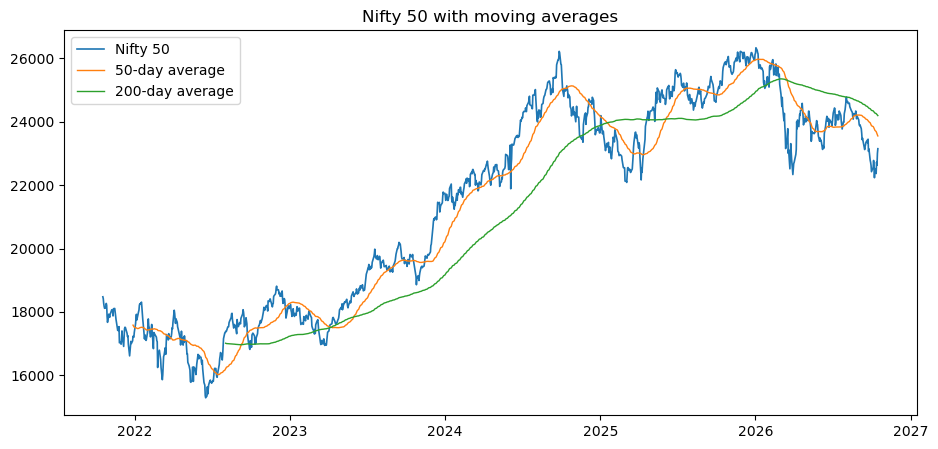

In [2]:
nifty = prices["NIFTY50"]

yearly = nifty.resample("YE").last().pct_change().dropna() * 100
yearly.index = yearly.index.year
print("Nifty 50 return by calendar year (%):")
print(yearly.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(nifty, label="Nifty 50", lw=1.2)
ax.plot(nifty.rolling(50).mean(), label="50-day average", lw=1)
ax.plot(nifty.rolling(200).mean(), label="200-day average", lw=1)
ax.set_title("Nifty 50 with moving averages")
ax.legend()
plt.show()

                      cagr_%  volatility_%  max_drawdown_%  sharpe
All 28 stocks          10.31         12.82          -16.56    0.26
Low-risk stocks only   11.45         12.06          -16.35    0.37
Nifty 50                4.62         13.90          -16.97   -0.17


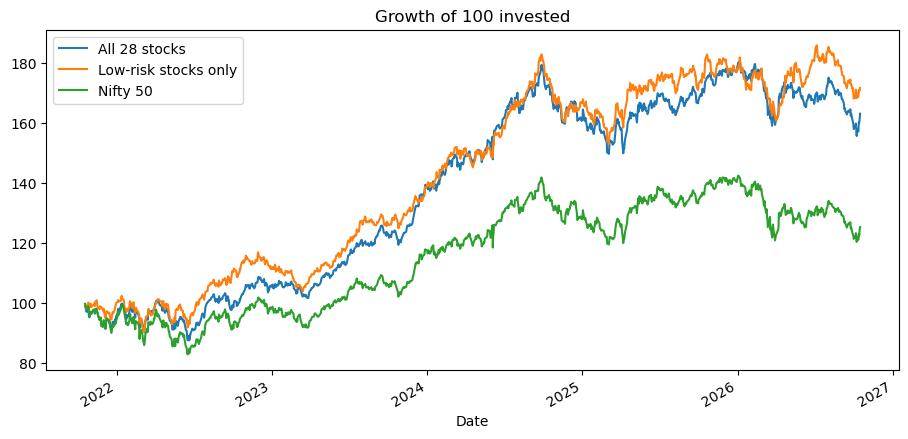

In [3]:
# Equal-weight portfolio: same amount in each of the 28 stocks, rebalanced daily
stock_returns = returns.drop(columns="NIFTY50")
low_risk = stocks.index[stocks["risk_level"] == "Low"]

port_all = stock_returns.mean(axis=1)
port_low = stock_returns[low_risk].mean(axis=1)
market = returns["NIFTY50"]

def summarize(r):
    growth = (1 + r).cumprod()
    years = (r.index[-1] - r.index[0]).days / 365.25
    cagr = growth.iloc[-1] ** (1 / years) - 1
    vol = r.std() * np.sqrt(252)
    dd = (growth / growth.cummax() - 1).min()
    return pd.Series({"cagr_%": cagr * 100, "volatility_%": vol * 100,
                      "max_drawdown_%": dd * 100, "sharpe": (cagr - 0.07) / vol})

compare = pd.DataFrame({
    "All 28 stocks": summarize(port_all),
    "Low-risk stocks only": summarize(port_low),
    "Nifty 50": summarize(market),
}).round(2).T
print(compare)

growth = pd.DataFrame({
    "All 28 stocks": (1 + port_all).cumprod() * 100,
    "Low-risk stocks only": (1 + port_low).cumprod() * 100,
    "Nifty 50": (1 + market).cumprod() * 100,
})
growth.plot(figsize=(11, 5), title="Growth of 100 invested")
plt.show()